In [ ]:
%load_ext autoreload
%autoreload 2

In [8]:

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import os
library_bin = os.path.join(sys.prefix, "Library", "bin")
if os.path.exists(library_bin):
    os.environ["PATH"] = library_bin + os.path.pathsep + os.environ.get("PATH", "")
    if hasattr(os, "add_dll_directory"):
        try:
            os.add_dll_directory(library_bin)
        except OSError:
            pass
import tomopy

# Point sys.path to the repository root
repo_root = Path.cwd().parent
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

import config
import src.phase_extraction as pe
import src.calibration as calib
import src.slit_analysis as sa

# Single-Angle Phase Map Extraction & Verification

Unsupported data type for _convert.
Unsupported data type for _convert.


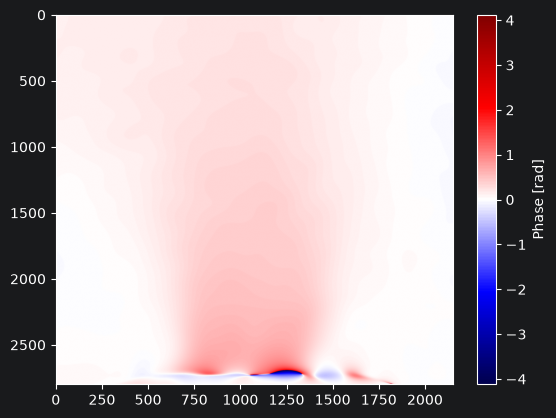

Detected Nozzle Edge (y-px): 2659
Detected Nozzle X-Range (px): [495, 1817]
Pixel-to-mm scaling factor: 0.004539 mm/px


In [9]:
# Path to 90 degree test scan
hdf5_path_90 = r"C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar\90_deg"

# Extract ROI and compute Fourier shift and phase unwrapping
roi = [2000, 5000, 1300, 3650]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path_90, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)
dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(
    ref_fourier_shifted, exp_fourier_shifted, dominant_frequency, debug=False
)

# Detect nozzle exit edge and horizontal bounds
y_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left, x_right = calib.detect_nozzle_x_range(ref_roi, y_edge, debug= False)

# Remove background tilt and zero the phase outside the jet
calibrated_phase_90, _ = calib.calibrate_phase(
    delta_phase_wrapped, y_edge, x_left, x_right, debug=True
)

# Spatial scaling calibration
NOZZLE_WIDTH_MM = 6.0
px_to_mm = calib.calculate_px_to_mm(x_left, x_right, NOZZLE_WIDTH_MM)

print(f"Detected Nozzle Edge (y-px): {y_edge}")
print(f"Detected Nozzle X-Range (px): [{x_left}, {x_right}]")
print(f"Pixel-to-mm scaling factor: {px_to_mm:.6f} mm/px")

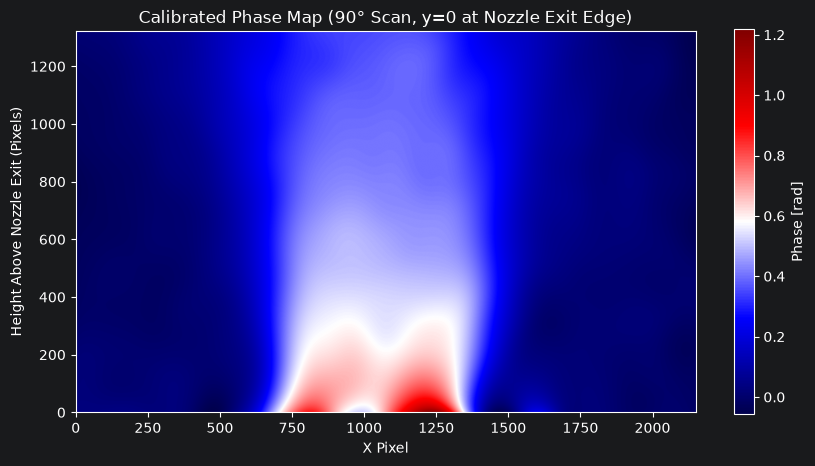

In [10]:
# Crop phase map up to 6.0 mm above nozzle and flip so y=0 is nozzle exit
MAX_HEIGHT_MM = 6.0
cropped_phase_90 = sa.crop_and_format_phase_map(
    calibrated_phase_90,
    nozzle_edge_y=y_edge,
    px_to_mm=px_to_mm,
    max_height_mm=MAX_HEIGHT_MM
)

# Visual check of calibrated 2D phase map
plt.figure(figsize=(10, 5))
plt.imshow(cropped_phase_90, origin="lower", cmap="seismic")
plt.title("Calibrated Phase Map (90° Scan, y=0 at Nozzle Exit Edge)")
plt.xlabel("X Pixel")
plt.ylabel("Height Above Nozzle Exit (Pixels)")
plt.colorbar(label="Phase [rad]")
plt.show()

# Batch Processing All 20 Angles using

In [11]:
# List of 20 projection angles between -20° and 180°
angles_deg = [-20, -10, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180]
base_path = r"C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar"

calibrated_maps = []

for angle in angles_deg:
    folder_path = rf"{base_path}\{int(angle)}_deg"
    print(f"Processing angle {angle:+.1f}°: {folder_path}")

    # Extract images using phase_extraction
    ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(folder_path, roi=roi)

    # Fourier transform & frequency shift
    ref_fourier_shifted = pe.get_fourier(ref_roi)
    exp_fourier_shifted = pe.get_fourier(exp_roi)
    dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

    # Extract unwrapped delta phase difference
    delta_phase_wrapped = pe.get_delta_phase_wrapped(
        ref_fourier_shifted, exp_fourier_shifted, dominant_frequency, debug=False
    )

    # Background tilt removal using fixed 90° bounds
    calibrated_phase, _ = calib.calibrate_phase(
        delta_phase_wrapped,
        nozzle_edge_y=y_edge,
        nozzle_left_px=x_left,
        nozzle_right_px=x_right,
        debug=False
    )

    # Crop to standardized grid (y=0 at nozzle exit, max height = 6.0 mm)
    cropped_phase = sa.crop_and_format_phase_map(
        calibrated_phase,
        nozzle_edge_y=y_edge,
        px_to_mm=px_to_mm,
        max_height_mm=MAX_HEIGHT_MM
    )

    calibrated_maps.append(cropped_phase)

# Enforce uniform dimensions across all views
min_h = min(m.shape[0] for m in calibrated_maps)
min_w = min(m.shape[1] for m in calibrated_maps)

# Stack into 3D array: (num_angles, height_px, width_px)
phase_stack = np.array([m[:min_h, :min_w] for m in calibrated_maps], dtype=np.float32)

print("\nPhase map extraction completed successfully.")
print(f"Output Stack Shape: {phase_stack.shape} (Angles, Height_px, Width_px)")

Processing angle -20.0°: C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar\-20_deg
Unsupported data type for _convert.
Unsupported data type for _convert.
Processing angle -10.0°: C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar\-10_deg
Unsupported data type for _convert.
Unsupported data type for _convert.
Processing angle +0.0°: C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar\0_deg
Unsupported data type for _convert.
Unsupported data type for _convert.
Processing angle +10.0°: C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar\10_deg
Unsupported data type for _convert.
Unsupported data type for _convert.
Processing angle +20.0°: C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar\20_deg
Unsupported data type for _convert.
Unsupported data type for _convert.
Processing angle +30.0°: C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar\30_deg
Unsupported data type for _convert.
Unsupporte

# Verification & TomoPy Dataset Formatting

Estimated Center of Rotation (CoR): 982.20 px


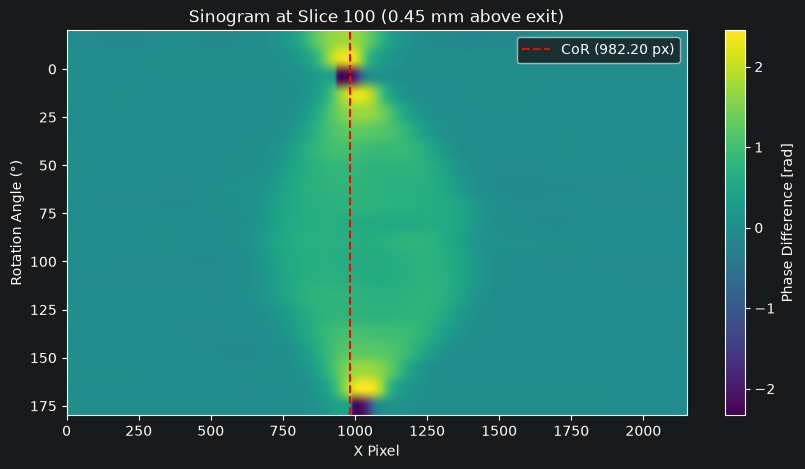

In [28]:
# Projection angles in radians for TomoPy
theta_rad = np.radians(angles_deg)

# Estimate Center of Rotation (CoR) on a slice near the nozzle exit (slice index 10)
sample_slice_idx = 100
rot_center = tomopy.find_center(
    phase_stack,
    theta_rad,
    init=phase_stack.shape[2] / 2.0,
    ind=sample_slice_idx,
    tol=0.5
)

# Convert to float to avoid numpy array formatting error
center_val = float(np.squeeze(rot_center))
print(f"Estimated Center of Rotation (CoR): {center_val:.2f} px")

# Visualize sinogram at sample height
plt.figure(figsize=(10, 5))
sinogram_slice = phase_stack[:, sample_slice_idx, :]
plt.imshow(
    sinogram_slice,
    aspect="auto",
    cmap="viridis",
    extent=[0, min_w, angles_deg[-1], angles_deg[0]]
)
plt.axvline(rot_center, color="red", linestyle="--", label=f"CoR ({center_val:.2f} px)")
plt.title(f"Sinogram at Slice {sample_slice_idx} ({sample_slice_idx * px_to_mm:.2f} mm above exit)")
plt.xlabel("X Pixel")
plt.ylabel("Rotation Angle (°)")
plt.colorbar(label="Phase Difference [rad]")
plt.legend()
plt.show()

# # Export dataset for TomoPy reconstruction
# output_dir = Path(r"C:\Users\vmlab\Documents\data\phase_maps\tomopy_prepared")
# output_dir.mkdir(parents=True, exist_ok=True)
#
# np.save(output_dir / "phase_stack_20angles.npy", phase_stack)
# np.save(output_dir / "theta_rad.npy", theta_rad)
# np.save(output_dir / "rot_center.npy", np.array([rot_center]))
# np.save(output_dir / "px_to_mm.npy", np.array([px_to_mm]))
#
# print(f"Saved TomoPy dataset to: {output_dir}")